In [1]:
# %% STEP 0 — Import & konfigurasi
import os, json, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

try:
    from IPython.display import display
except ImportError:
    display = print

# ====== KONFIGURASI ======
DATA_DIR   = r"E:\BIG DATA\praktikum_9\processed_data"
OUT_DIR    = "output"
IMG_SIZE   = (48, 48)
BATCH      = 64
EPOCHS     = 40
LR         = 1e-3
TEST_SIZE  = 0.2
SEED       = 42
USE_CLASS_WEIGHT = True
VALID_EXT  = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Dataset ada? ", os.path.exists(DATA_DIR))

TensorFlow: 2.21.0
Dataset ada?  True


FOLDER angry
FOLDER disgust
FOLDER fear
FOLDER happy
FOLDER neutral
FOLDER sad
FOLDER surprise
Total gambar : 49,779
Jumlah kelas : 7 -> ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


sumber,-,All
label,,
angry,5920,5920
disgust,5920,5920
fear,5920,5920
happy,11398,11398
neutral,8166,8166
sad,6535,6535
surprise,5920,5920
All,49779,49779


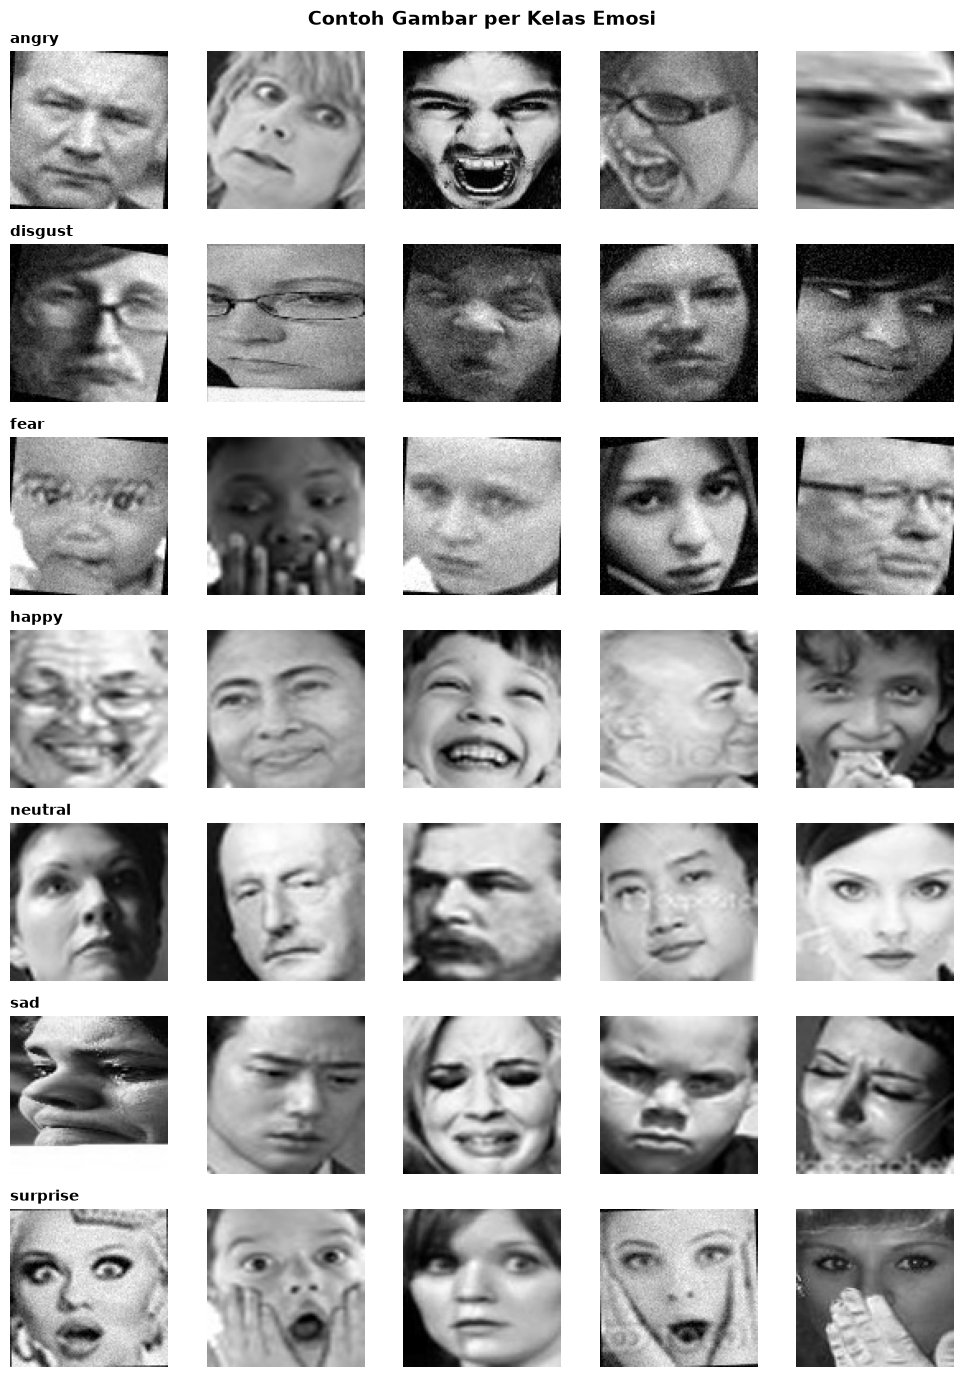

In [2]:
# %% LANGKAH 1 — Pemahaman dataset
for name in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, name)
    print("FOLDER" if os.path.isdir(p) else "file  ", name)

rows = []
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith(VALID_EXT):
            rel = os.path.relpath(root, DATA_DIR).split(os.sep)
            rows.append({
                "path": os.path.join(root, f),
                "label": os.path.basename(root),
                "sumber": rel[0] if len(rel) > 1 else "-",
            })
df = pd.DataFrame(rows)
assert len(df) > 0, "Tidak ada gambar ditemukan. Periksa DATA_DIR!"

class_names = sorted(df["label"].unique())
NUM_CLASSES = len(class_names)
print(f"Total gambar : {len(df):,}")
print(f"Jumlah kelas : {NUM_CLASSES} -> {class_names}")
assert 2 <= NUM_CLASSES <= 20, "Jumlah kelas tidak wajar: cek nama folder kelas."
display(pd.crosstab(df["label"], df["sumber"], margins=True))

# Contoh visual tiap emosi
N_PER_CLASS = 5
fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(N_PER_CLASS * 2, NUM_CLASSES * 2))
for i, c in enumerate(class_names):
    sample = df[df.label == c].sample(N_PER_CLASS, random_state=SEED)
    for j, p in enumerate(sample["path"]):
        ax = axes[i, j]
        ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.axis("off")
        if j == 0: ax.set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Contoh Gambar per Kelas Emosi", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "1_sample_per_class.png"), dpi=110, bbox_inches="tight")
plt.show()


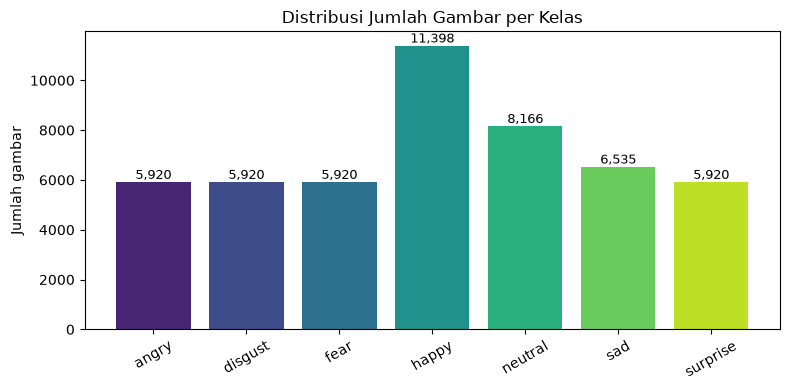

label
angry        5920
disgust      5920
fear         5920
happy       11398
neutral      8166
sad          6535
surprise     5920

Rasio kelas terbanyak : terkecil = 1.93x
Kelas terbanyak : happy | Kelas tersedikit : angry
=> Ada class imbalance.
Ukuran gambar (W,H) : [((96, 96), 1500)]
Mode warna          : {'RGB': 1500}  (L = grayscale, RGB = berwarna)
Brightness rata-rata: 129.4  | Kontras (std) rata-rata: 49.2
Gambar sangat gelap (<40): 5  | kontras rendah (<20): 11


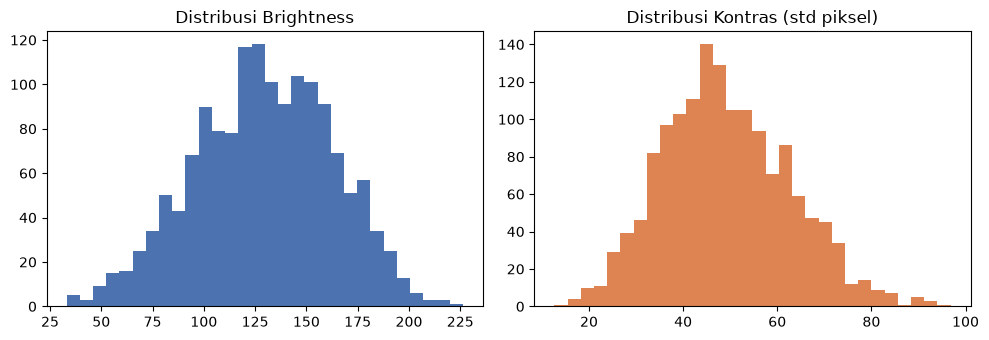

In [3]:
# %% LANGKAH 2 — EDA
class_counts = df["label"].value_counts().reindex(class_names)
imbalance_ratio = class_counts.max() / class_counts.min()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=plt.cm.viridis(np.linspace(0.1, 0.9, NUM_CLASSES)))
for b, v in zip(bars, class_counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi Jumlah Gambar per Kelas"); ax.set_ylabel("Jumlah gambar")
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_class_distribution.png"), dpi=120, bbox_inches="tight")
plt.show()

print(class_counts.to_string())
print(f"\nRasio kelas terbanyak : terkecil = {imbalance_ratio:.2f}x")
print("Kelas terbanyak :", class_counts.idxmax(), "| Kelas tersedikit :", class_counts.idxmin())
print("=> Ada class imbalance." if imbalance_ratio > 1.5 else "=> Distribusi relatif seimbang.")

# Ukuran gambar, mode warna, kualitas
n_sample = min(1500, len(df))
sizes, modes, bright, contrast = [], [], [], []
for p in df.sample(n_sample, random_state=SEED)["path"]:
    with Image.open(p) as im:
        sizes.append(im.size); modes.append(im.mode)
        g = np.asarray(im.convert("L"), dtype="float32")
        bright.append(g.mean()); contrast.append(g.std())

print("Ukuran gambar (W,H) :", Counter(sizes).most_common(5))
print("Mode warna          :", dict(Counter(modes)), " (L = grayscale, RGB = berwarna)")
print(f"Brightness rata-rata: {np.mean(bright):.1f}  | Kontras (std) rata-rata: {np.mean(contrast):.1f}")
print(f"Gambar sangat gelap (<40): {(np.array(bright) < 40).sum()}  | kontras rendah (<20): {(np.array(contrast) < 20).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(bright, bins=30, color="#4c72b0"); ax[0].set_title("Distribusi Brightness")
ax[1].hist(contrast, bins=30, color="#dd8452"); ax[1].set_title("Distribusi Kontras (std piksel)")
plt.tight_layout(); plt.show()

img_stats = {
    "common_size": list(Counter(sizes).most_common(1)[0][0]),
    "modes": dict(Counter(modes)),
    "mean_brightness": float(np.mean(bright)),
    "mean_contrast": float(np.mean(contrast)),
    "n_sampled": int(n_sample),
}

  dimuat 5,000/49,779
  dimuat 10,000/49,779
  dimuat 15,000/49,779
  dimuat 20,000/49,779
  dimuat 25,000/49,779
  dimuat 30,000/49,779
  dimuat 35,000/49,779
  dimuat 40,000/49,779
  dimuat 45,000/49,779
Selesai dalam 814.9 dtk | X: (49779, 48, 48, 1) | file rusak dilewati: 0
Train: 39,823 | Test: 9,956
Contoh label int -> one-hot: 2 -> [0. 0. 1. 0. 0. 0. 0.]
Rentang piksel: 0.0 - 1.0
Class weight: {'angry': 1.2, 'disgust': 1.2, 'fear': 1.2, 'happy': 0.62, 'neutral': 0.87, 'sad': 1.09, 'surprise': 1.2}


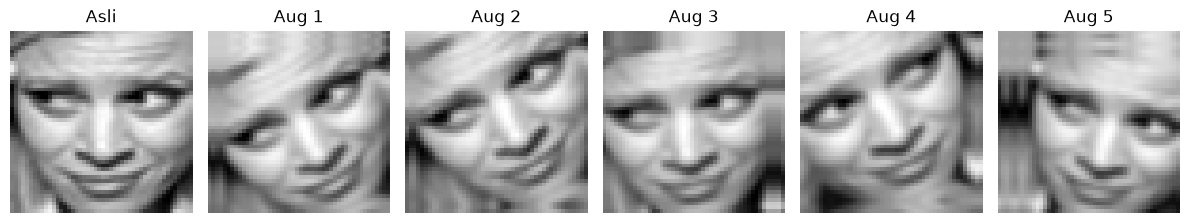

In [4]:
# %% LANGKAH 3 — Pra-pemrosesan
label2idx = {c: i for i, c in enumerate(class_names)}

def load_image(path):
    try:
        with Image.open(path) as im:
            return np.asarray(im.convert("L").resize(IMG_SIZE), dtype="uint8")
    except Exception:
        return None

t0 = time.time()
X_list, y_list, bad = [], [], 0
for i, (p, lab) in enumerate(zip(df["path"], df["label"])):
    arr = load_image(p)
    if arr is None:
        bad += 1; continue
    X_list.append(arr); y_list.append(label2idx[lab])
    if (i + 1) % 5000 == 0: print(f"  dimuat {i+1:,}/{len(df):,}")

X = np.array(X_list)[..., np.newaxis]
y = np.array(y_list)
print(f"Selesai dalam {time.time()-t0:.1f} dtk | X: {X.shape} | file rusak dilewati: {bad}")

# Normalisasi 0-1
X = X.astype("float32") / 255.0

# Split 80/20 (stratified)
X_train, X_test, y_train_int, y_test_int = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

# One-hot encoding
y_train = to_categorical(y_train_int, NUM_CLASSES)
y_test  = to_categorical(y_test_int,  NUM_CLASSES)

print(f"Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}")
print("Contoh label int -> one-hot:", y_train_int[0], "->", y_train[0])
print("Rentang piksel:", X.min(), "-", X.max())

class_weight = None
if USE_CLASS_WEIGHT:
    w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train_int)
    class_weight = {i: float(v) for i, v in enumerate(w)}
    print("Class weight:", {class_names[i]: round(v, 2) for i, v in class_weight.items()})

# Augmentasi (aktif hanya saat training)
augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

img0 = X_train[0:1]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(img0[0, ..., 0], cmap="gray"); axes[0].set_title("Asli"); axes[0].axis("off")
for k in range(1, 6):
    axes[k].imshow(augment(img0, training=True)[0, ..., 0], cmap="gray")
    axes[k].set_title(f"Aug {k}"); axes[k].axis("off")
plt.tight_layout(); plt.show()

In [5]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

In [6]:
# ================== LANGKAH 4A — MEMBANGUN MODEL CNN ==================
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Bersihkan sesi lama supaya memori & nama layer tidak menumpuk
tf.keras.backend.clear_session()

# --- Parameter (boleh diubah) ---
BATCH   = 32                      # diperkecil agar hemat memori
EPOCHS  = 40
LR      = 1e-3
FILTERS = (32, 64, 128, 256)      # jika masih error memori: (32, 64, 128, 128)

# --- Augmentasi (hanya aktif saat training) ---
augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

# --- Blok konvolusi ---
def conv_block(x, filters, pool=True, drop=0.25, name=None):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name)(x)
    x = layers.BatchNormalization()(x)
    if pool:
        x = layers.MaxPooling2D()(x)
    if drop:
        x = layers.Dropout(drop)(x)
    return x

# --- Arsitektur ---
inputs = layers.Input(shape=IMG_SIZE + (1,), name="input_image")
x = augment(inputs)
x = conv_block(x, FILTERS[0])                                        # 48 -> 24
x = conv_block(x, FILTERS[1])                                        # 24 -> 12
x = conv_block(x, FILTERS[2])                                        # 12 -> 6
x = conv_block(x, FILTERS[3], pool=False, drop=0.0, name="last_conv")  # 6x6 (dipakai Grad-CAM)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="emotion")(x)

model = models.Model(inputs, outputs, name="fer_cnn")
model.compile(
    optimizer=Adam(LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "fer_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 6, 6, 256)      │         1,02

 Total params: 1,244,135 (4.75 MB)

 Trainable params: 1,241,703 (4.74 MB)

 Non-trainable params: 2,432 (9.50 KB)

In [7]:
# ================== LANGKAH 4B — TRAINING ==================
import os, json, time
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

ckpt_path = os.path.join(OUT_DIR, "fer_cnn_best.keras")
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=8,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                      min_lr=1e-6, verbose=1),
]

t0 = time.time()
h = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),         
    epochs=EPOCHS,
    batch_size=BATCH,
    class_weight=class_weight,
    callbacks=callbacks,
)
print(f"\nTotal waktu training: {(time.time() - t0) / 60:.1f} menit")

# Simpan riwayat training
history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
with open(os.path.join(OUT_DIR, "history.json"), "w") as f:
    json.dump(history, f)

Epoch 1/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 1343s 1s/step - accuracy: 0.2497 - loss: 2.0815 - val_accuracy: 0.3776 - val_loss: 1.6024 - learning_rate: 0.0010
Epoch 2/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 445s 358ms/step - accuracy: 0.4236 - loss: 1.5630 - val_accuracy: 0.4907 - val_loss: 1.3709 - learning_rate: 0.0010
Epoch 3/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 439s 352ms/step - accuracy: 0.4876 - loss: 1.4066 - val_accuracy: 0.5387 - val_loss: 1.2524 - learning_rate: 0.0010
Epoch 4/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 434s 349ms/step - accuracy: 0.5195 - loss: 1.3225 - val_accuracy: 0.5520 - val_loss: 1.2369 - learning_rate: 0.0010
Epoch 5/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 439s 352ms/step - accuracy: 0.5470 - loss: 1.2651 - val_accuracy: 0.4965 - val_loss: 1.4870 - learning_rate: 0.0010
Epoch 6/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 427s 343ms/step - accuracy: 0.5640 - loss: 1.2191 - val_accuracy: 0.5874 - val_loss: 1.1169 - learning_rate: 0.0010
Epoch 7/40
1245/1245 ━━━━━━━━━━━━━━━━━━━━ 428s 343ms/s

In [9]:
# ================== LANGKAH 4C — SIMPAN MODEL ==================
import pandas as pd

TEST_SIZE = 0.2

model.save(os.path.join(OUT_DIR, "final_fer_cnn_model.keras"))
with open(os.path.join(OUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

train_counts = pd.Series(y_train_int).map(lambda i: class_names[i]).value_counts().reindex(class_names)
test_counts  = pd.Series(y_test_int).map(lambda i: class_names[i]).value_counts().reindex(class_names)

summary = {
    "n_total": int(len(X)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "n_classes": int(NUM_CLASSES),
    "class_names": class_names,
    "class_counts": {k: int(v) for k, v in class_counts.items()},
    "train_counts": {k: int(v) for k, v in train_counts.items()},
    "test_counts":  {k: int(v) for k, v in test_counts.items()},
    "imbalance_ratio": float(imbalance_ratio),
    "img_size": list(IMG_SIZE),
    "img_stats": img_stats,
    "split": f"{int((1 - TEST_SIZE) * 100)}:{int(TEST_SIZE * 100)}",
}
with open(os.path.join(OUT_DIR, "dataset_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Model & ringkasan dataset tersimpan di:", os.path.abspath(OUT_DIR))

Model & ringkasan dataset tersimpan di: e:\BIG DATA\praktikum_9\output


In [10]:
# %% LANGKAH 5 — Evaluasi
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Test : {acc*100:.2f}%")
print(f"Loss Test    : {loss:.4f}")

probs  = model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(probs, axis=1)

report_dict = classification_report(y_test_int, y_pred, target_names=class_names,
                                    digits=3, zero_division=0, output_dict=True)
print("\nCLASSIFICATION REPORT\n")
print(classification_report(y_test_int, y_pred, target_names=class_names, digits=3, zero_division=0))

report_df = pd.DataFrame(report_dict).T.round(4)
report_df.to_csv(os.path.join(OUT_DIR, "classification_report.csv"))
display(report_df)

pm, rm, fm, _ = precision_recall_fscore_support(y_test_int, y_pred, average="macro", zero_division=0)
pw, rw, fw, _ = precision_recall_fscore_support(y_test_int, y_pred, average="weighted", zero_division=0)
metrics = {"accuracy": float(accuracy_score(y_test_int, y_pred)), "loss": float(loss),
           "macro":    {"precision": float(pm), "recall": float(rm), "f1": float(fm)},
           "weighted": {"precision": float(pw), "recall": float(rw), "f1": float(fw)},
           "per_class": {c: {k: float(report_dict[c][k]) for k in ("precision", "recall", "f1-score", "support")}
                         for c in class_names}}
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

# Interpretasi otomatis
f1s = {c: metrics["per_class"][c]["f1-score"] for c in class_names}
best, worst = max(f1s, key=f1s.get), min(f1s, key=f1s.get)
print(f"- Akurasi {metrics['accuracy']*100:.1f}% -> model {'mampu mengenali emosi dengan cukup baik' if metrics['accuracy']>=0.7 else 'masih perlu ditingkatkan'}.")
print(f"- F1 macro {fm:.3f} vs weighted {fw:.3f}: "
      f"{'selisih kecil, performa merata antar kelas.' if abs(fm-fw) < 0.03 else 'selisih cukup besar, ada kelas yang tertinggal.'}")
print(f"- Kelas paling mudah dikenali : {best} (F1 = {f1s[best]:.3f})")
print(f"- Kelas paling sulit dikenali : {worst} (F1 = {f1s[worst]:.3f})")

Akurasi Test : 65.46%
Loss Test    : 0.9920

CLASSIFICATION REPORT

              precision    recall  f1-score   support

       angry      0.608     0.508     0.554      1184
     disgust      0.637     0.848     0.727      1184
        fear      0.452     0.549     0.496      1184
       happy      0.917     0.772     0.838      2280
     neutral      0.651     0.552     0.598      1633
         sad      0.512     0.523     0.517      1307
    surprise      0.699     0.774     0.734      1184

    accuracy                          0.655      9956
   macro avg      0.639     0.647     0.638      9956
weighted avg      0.669     0.655     0.656      9956



,precision,recall,f1-score,support
angry,0.6081,0.5084,0.5538,1184.0000
disgust,0.6367,0.8480,0.7273,1184.0000
fear,0.4517,0.5490,0.4956,1184.0000
happy,0.9167,0.7719,0.8381,2280.0000
neutral,0.6508,0.5524,0.5975,1633.0000
sad,0.5124,0.5226,0.5174,1307.0000
surprise,0.6987,0.7736,0.7343,1184.0000
accuracy,0.6546,0.6546,0.6546,0.6546
macro avg,0.6393,0.6466,0.6377,9956.0000
weighted avg,0.6688,0.6546,0.6565,9956.0000


- Akurasi 65.5% -> model masih perlu ditingkatkan.
- F1 macro 0.638 vs weighted 0.656: selisih kecil, performa merata antar kelas.
- Kelas paling mudah dikenali : happy (F1 = 0.838)
- Kelas paling sulit dikenali : fear (F1 = 0.496)


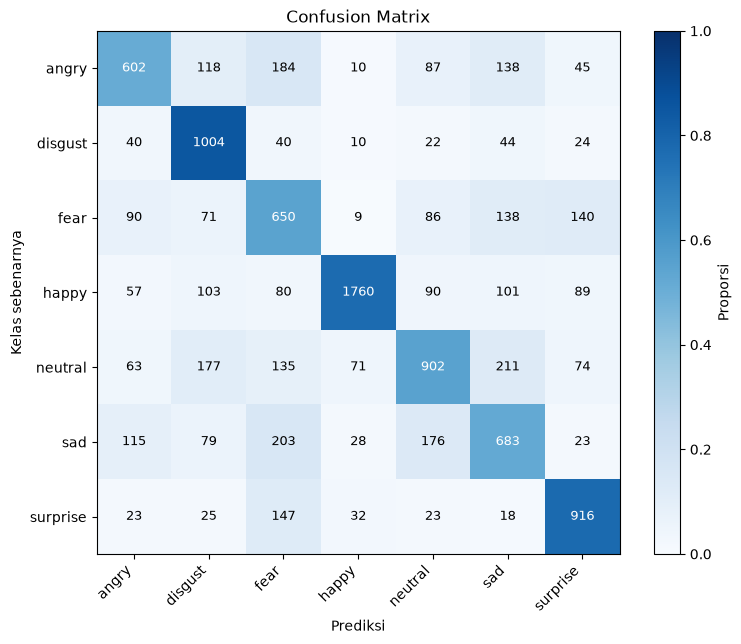

Sering tertukar: neutral -> diprediksi sad (211 gambar)
Sering tertukar: sad -> diprediksi fear (203 gambar)
Sering tertukar: angry -> diprediksi fear (184 gambar)


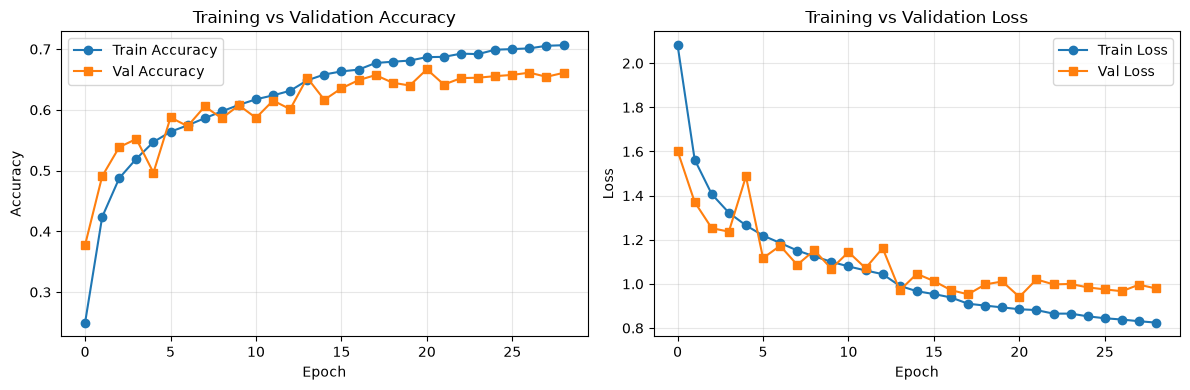

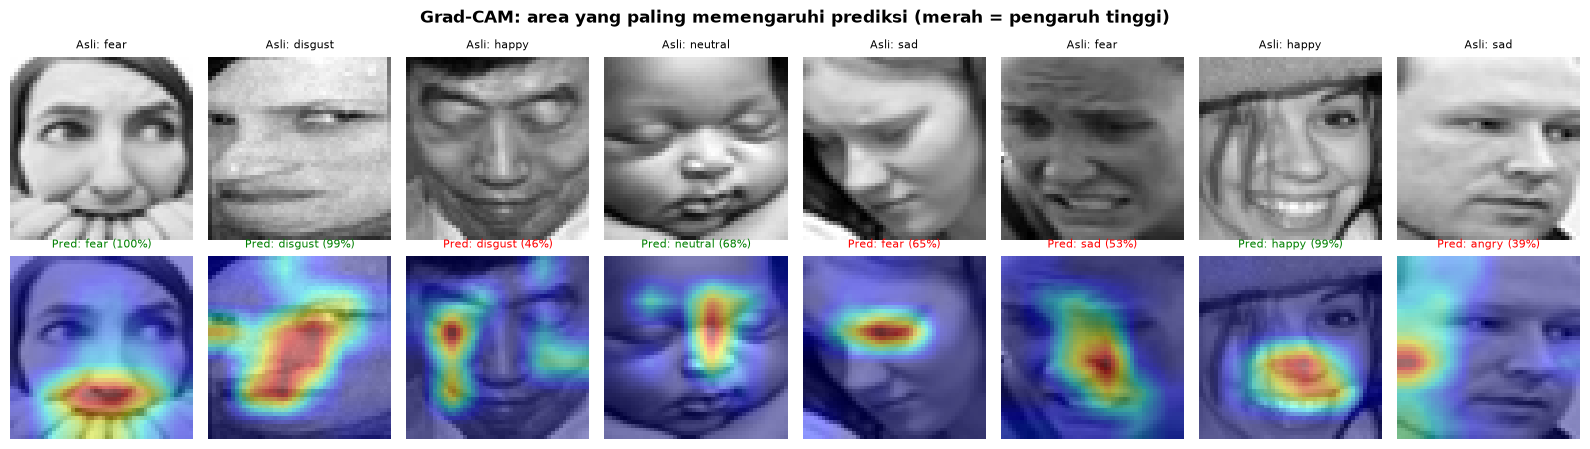

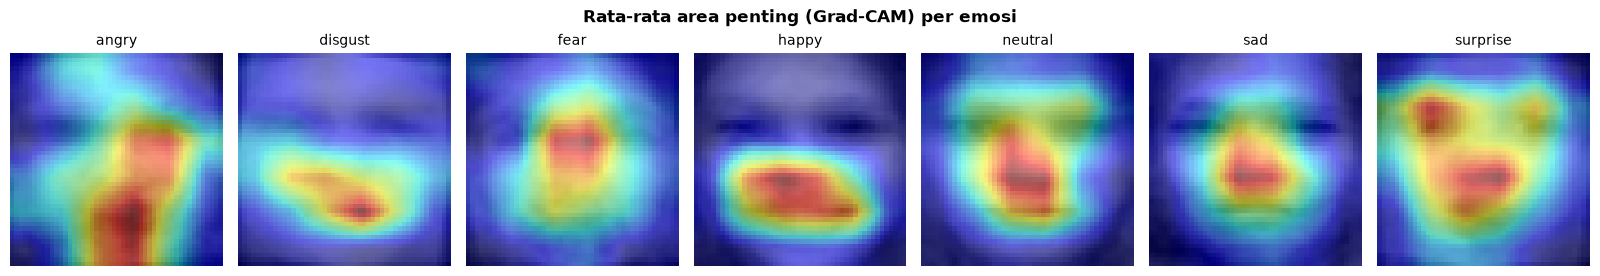

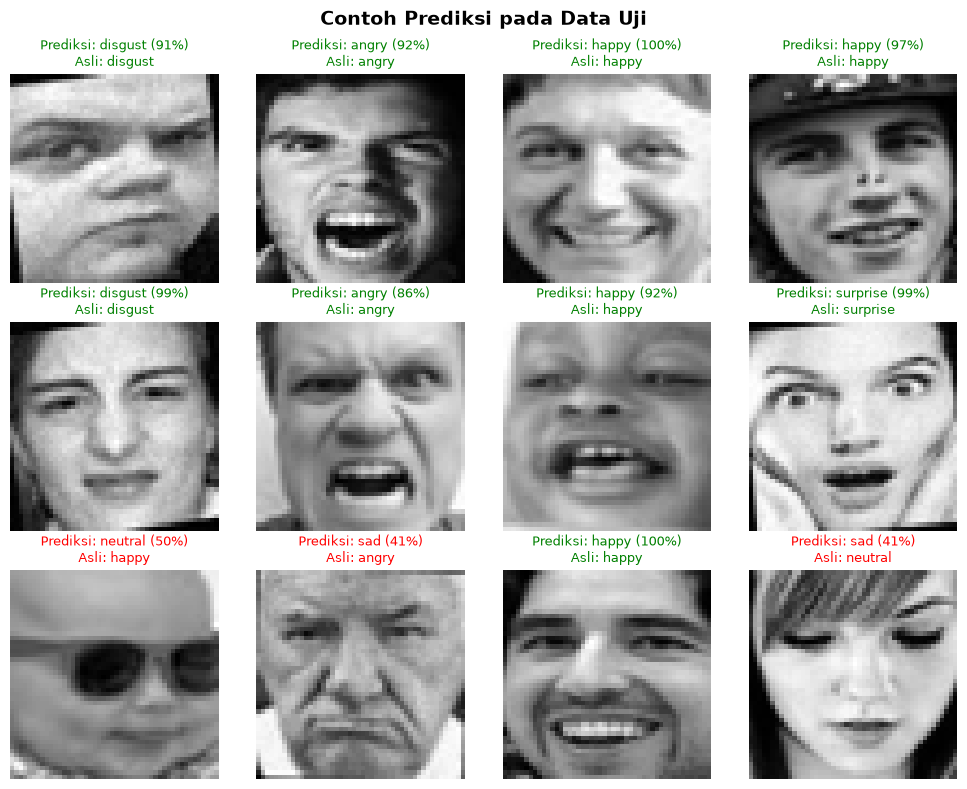

Model berhasil di-load ulang. Output shape: (None, 7)

File di folder output/:
 - 1_sample_per_class.png
 - 2_class_distribution.png
 - 3_confusion_matrix.png
 - 4_training_curves.png
 - 5_gradcam_samples.png
 - 6_gradcam_per_class.png
 - 7_sample_predictions.png
 - class_names.json
 - classification_report.csv
 - confusion_matrix.json
 - dataset_summary.json
 - fer_cnn_best.keras
 - final_fer_cnn_model.keras
 - history.json
 - metrics.json


In [12]:
# %% LANGKAH 6 — Visualisasi
# 6.1 Confusion matrix
cm = confusion_matrix(y_test_int, y_pred, labels=range(NUM_CLASSES))
cm_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
with open(os.path.join(OUT_DIR, "confusion_matrix.json"), "w") as f:
    json.dump({"labels": class_names, "matrix": cm.tolist()}, f)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proporsi")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm_pct[i, j] > 0.5 else "black", fontsize=9)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Kelas sebenarnya"); ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_confusion_matrix.png"), dpi=120, bbox_inches="tight")
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:3], off.shape))[0]
for i, j in top:
    print(f"Sering tertukar: {class_names[i]} -> diprediksi {class_names[j]} ({off[i, j]} gambar)")

# 6.2 Grafik akurasi & loss
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (m, t) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
    a.plot(history[m], "o-", label=f"Train {t}")
    a.plot(history[f"val_{m}"], "s-", label=f"Val {t}")
    a.set_title(f"Training vs Validation {t}"); a.set_xlabel("Epoch"); a.set_ylabel(t)
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "4_training_curves.png"), dpi=120, bbox_inches="tight")
plt.show()

# 6.3 Grad-CAM (feature importance)
def grad_cam(model, img, layer_name="last_conv"):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    x = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x, training=False)
        idx = int(tf.argmax(preds[0]))
        score = preds[:, idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize(IMG_SIZE, Image.BILINEAR), dtype="float32") / 255.0
    return cam, idx, float(preds[0, idx])

rng = np.random.RandomState(SEED)
pick = rng.choice(len(X_test), 8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for k, i in enumerate(pick):
    cam, pi, pr = grad_cam(model, X_test[i])
    axes[0, k].imshow(X_test[i, ..., 0], cmap="gray"); axes[0, k].axis("off")
    axes[0, k].set_title(f"Asli: {class_names[y_test_int[i]]}", fontsize=8)
    axes[1, k].imshow(X_test[i, ..., 0], cmap="gray")
    axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
    axes[1, k].set_title(f"Pred: {class_names[pi]} ({pr*100:.0f}%)", fontsize=8,
                         color="green" if pi == y_test_int[i] else "red")
plt.suptitle("Grad-CAM: area yang paling memengaruhi prediksi (merah = pengaruh tinggi)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "5_gradcam_samples.png"), dpi=120, bbox_inches="tight")
plt.show()

# Rata-rata Grad-CAM per kelas
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(2.3 * NUM_CLASSES, 2.8))
for c in range(NUM_CLASSES):
    idxs = np.where((y_test_int == c) & (y_pred == c))[0][:80]
    if len(idxs) == 0:
        axes[c].axis("off"); continue
    mean_cam = np.mean([grad_cam(model, X_test[i])[0] for i in idxs], axis=0)
    mean_img = X_test[idxs].mean(axis=0)[..., 0]
    axes[c].imshow(mean_img, cmap="gray"); axes[c].imshow(mean_cam, cmap="jet", alpha=0.5)
    axes[c].set_title(class_names[c], fontsize=10); axes[c].axis("off")
plt.suptitle("Rata-rata area penting (Grad-CAM) per emosi", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "6_gradcam_per_class.png"), dpi=120, bbox_inches="tight")
plt.show()

# 6.4 Contoh prediksi vs label asli
pick = rng.choice(len(X_test), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for a, i in zip(axes.ravel(), pick):
    p = int(y_pred[i]); t = int(y_test_int[i])
    a.imshow(X_test[i, ..., 0], cmap="gray")
    a.set_title(f"Prediksi: {class_names[p]} ({probs[i, p]*100:.0f}%)\nAsli: {class_names[t]}",
                color="green" if p == t else "red", fontsize=9)
    a.axis("off")
plt.suptitle("Contoh Prediksi pada Data Uji", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "7_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

# %% Cek model bisa di-load ulang
loaded = tf.keras.models.load_model(os.path.join(OUT_DIR, "final_fer_cnn_model.keras"), compile=False)
print("Model berhasil di-load ulang. Output shape:", loaded.output_shape)
print("\nFile di folder output/:")
for fn in sorted(os.listdir(OUT_DIR)): print(" -", fn)
